## Telrad Finder Charts - Tirion Style
**[5 Oct 2026]**

In 2001, I wrote a small handbook with Telrad finder charts called the **SMAS 50**. I've often thought about revising it, and in particular in making new similar charts -- I find them useful for teaching, public talks, and so on. I made that first **SMAS 50** book by making charts using the old Macintosh version of *The Sky* by Software Bisque. Software I've had since then (notably *Starry Night* which seems to have not been updated in many years now) has failed to make the nice charts of that old version -- what I call "Tirion Style," after Wil Tirion (of *Cambridge Star Atlas*, *Sky Atlas 2000*, and *Uranometria* fame). The modern ***Pocket Sky Atlas*** has the same aesthetic, defined by the clear focus on naked-eye (or nearly) stars for limiting magnitude, and the classic symbols used by Tirion for deep sky objects (which I've grown used to after many decades of observing!).

So since I made the original **SMAS 50**, I've kept my old blue-and-white Power Macintosh G3, so I could once again fire up *The Sky* and make some new charts. So this weekend, after a 25-year hiatus, I set up that old G3. I remembered my login and password! And to my shock and dismay, *the software was not installed on the machine!* Even more distressing, I had a shelf of all my old software CDs in the house in Illinois, and when we moved here to New York last year, *I have no idea where they ended up!* 

When I was working on this 25 years ago, I did not have any easy way to generate my own graphic output, but realized that today python plotting made it possible I could probably from a database of stars (like Hoffleit's *Yale Bright Star Catalog*) just make my own charts. But then I was like "someone *must* have trying to make python star charting software!" And they have!

I found the **starplot** python library by Steve Berardi! This notebook is to develop my use of **starplot** in my quest to make the Telrad charts I'm after!
* **starplot** [Documentation: https://starplot.dev](https://starplot.dev)
* **starplot** [Github: https://github.com/steveberardi/starplot/](https://github.com/steveberardi/starplot/)


### Jupyter/Python Setup

In [1]:
print("Welcome to MY JUPYTER TELRAD CHART PLOTTER.")

# Comment: My Standard Imports
import math
import numpy as np
import matplotlib.pyplot as plt

# Comment: Starplot Imports
import starplot as sp
from starplot.styles import PlotStyle, MarkerStyle

# Comment: Other utilities I need
import bisect

# These are needed to display SVG rendering inline
import io
import tempfile
from pathlib import Path
from IPython.display import Image, SVG, display

# Suppress Jupyter Warnings, Download Logs, etc.
# Starplot generates a lot of these, so this
# suppresses them to keep the notebook readable
import warnings
import logging
import os

warnings.filterwarnings("ignore")  # suppress Python warnings (e.g., DeprecationWarning, UserWarning)
logging.getLogger().setLevel(logging.ERROR) # suppress standard logging warnings


print("==> Imports complete.")

Welcome to MY JUPYTER TELRAD CHART PLOTTER.
==> Imports complete.


### **TIRION DIRECTIVES -- Development**

#### Magnitude Binning

Bin stellar magnitudes into 8 different sizes for stellar plotting. Tirion centers magnitue bins on integer magnitudes, spread 0.5 magnitude above and below the center of the bin (e.g. see his explanation in *Cambridge Star Atlas*; I believe *Uranometria* uses a smooth taper of sizes across magnitudes). The bins used here then are:
* `[-1.5, -0.5]` = Mag -1 bin
* `[-0.5, 0.5]` = Mag 0 bin
* `[0.5, 1.5]` = Mag 1 bin
* `[1.5, 2.5]` = Mag 2 bin
* `[2.5, 3.5]` = Mag 3 bin
* `[3.5, 4.5]` = Mag 4 bin
* `[4.5, 5.5]` = Mag 5 bin
* `[5.5, 6.5]` = Mag 6 bin

In [2]:
# [5 Oct 2026] As I was working I found in the documentation on "callables"
# an example of plotting size by magnitude: https://starplot.dev/reference-callables/

# Define ends of the magnitude bins centered on integer magnitudes
MAG_BINS = [
    (-1.5, -0.5),
    (-0.5,  0.5),
    ( 0.5,  1.5),
    ( 1.5,  2.5),
    ( 2.5,  3.5),
    ( 3.5,  4.5),
    ( 4.5,  5.5),
    ( 5.5,  6.5),
]

# Also define the cutoff boundaries between the bins
BIN_CUTOFFS = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5]

# For each of these bins, we are going to plot circles of 8 diferent discrete sizes. For each of the above
# bins, these are the stellar plotting size in POINTS I saw somewhere starplot switched from pts->pixels, so
# come back to this later -- I care about printing, not  screens! So figure out the right PIX <-> PTS conversion

# STAR_SIZES = [18.0, 13.5, 11.0, 8.8, 6.8, 5.0, 3.5, 2.2]   # original scaling guess
STAR_SIZES = [42.0, 39.0, 36.0, 33.0, 30.0, 27.0, 24.0, 21.0] 

# This function takes as input the stellar magnitude,
# and based on the bins noted above, returns the 
# starsize noted here for plotting. This is essentially
# the map from magnitude --> discrete star plotting size
def getStarSize(magnitude: float) -> float:
    idx = bisect.bisect_right(BIN_CUTOFFS, magnitude) # bisect_right finds bin index (0 to 7) for given magnitude
    return STAR_SIZES[idx]

#### Magnitude Tapered Stellar Size 

In [2]:
# [17 Oct 2026] Got all my getStarSize() and Tirion directives working, but in examining my old SMAS50 charts
# it seems my star sizes might be tapered -- this is what was done in Uranometria, so maybe that is what 
# the SKY software did. The appearance I am after then is then there is a max star size and min star size, so
# this function pins those sizes, then for any magnitude that it is passed to it, linearly tapers the size to
# the requested value.

def getTaperedStarSize(
    magnitude: float,              # passed value to find taper size for
    minMag: float = -1.5,          # brightest mangitude in my taper
    maxMag: float = 6.5,           # smallest magnitude in my taper
    minSize: float = 10.0,         # printed minimum taper size
    maxSize: float = 100.0,        # printed maximum taper size
) -> float:
    """Get star size as a smooth taper between minSize and maxSize.

    Args:
        magnitude: Stellar magnitude of the star.
        minMag: Brightest magnitude bound (corresponds to maxSize). nomrally -1.5 (Sirius)
        maxMag: Faintest magnitude bound (corresponds to minSize). visual = 6.5.
        minSize: Size (in points) for stars at or brighter than minMag.
        maxSize: Size (in points) for stars at or fainter than maxMag.

    Returns:
        Interpolated star marker size in points.
    """
    
    # Clamp magnitude within [minMag, maxMag] bounds
    clamped_mag = max(minMag, min(magnitude, maxMag))

    # Calculate normalized position: 0.0 (brightest) to 1.0 (faintest)
    t = (clamped_mag - minMag) / (maxMag - minMag)

    # Linearly interpolate from max_size down to min_size
    return maxSize - t * (maxSize - minSize)

#### Telrad Rings

In [3]:
from starplot import MapPlot
from starplot.styles import PolygonStyle

def makeTelrad(
    plot: MapPlot,
    ra: float,
    dec: float,
    color: str = "#FF0000",
    stroke_width: float = 4.0,
):
    """Plots a set of 3 concentric Telrad rings at a given (RA, DEC).

    Args:
        plot: Starplot MapPlot or ZenithPlot instance.
        ra: Right Ascension in degrees (or hours * 15).
        dec: Declination in degrees.
        color: Stroke color for the rings (default is red '#FF0000').
        stroke_width: Line width in points.
    """
    # Diameter of rings in Telrad Reticle: 0.5d, 2.0d, and 4.0d -> radii are 1/2 these values
    telrad_radii = [0.25, 1.0, 2.0]

    ring_style = PolygonStyle(
        fill=None,                  # No fill (transparent interior)
        stroke=color,               # Red ring outline
        stroke_width=stroke_width,  # Thickness of ring line
    )

    for radius in telrad_radii:
        plot.circle(
            center=(ra, dec),
            radius_degrees=radius,
            style=ring_style,
        )

#### Names -- Label Cleanup

**[20 Oct 2026]** Because starplot pulls from the OpenNGC, some of its labels are wonky. I noticed this when it was labeling galaxies that would show up as "NGC 6817 NED01". Additionally it would label objects multiple times.This bit of code was written to clean up labels like this to just the NGC numbers. I haven't seen it on anything except galaxies, so may have to be extended in the future.

In [4]:
import re   # regular expressions, for operations on name labels (e.g. NED labels on gx from OpenNGC)

trackLabels = set()   # since we make several evaluations to plot, this keeps track of if a label has been used or not

def standardLabel(dso) -> str:
    """
    Strips 'NED' suffixes and ensures only ONE label is drawn per base NGC object.
    Returns "" for duplicates or sub-components to suppress extra labels.
    Example: "NGC 6817 NED01" -> "6817"
    """
    if not dso.name:
        return ""
    
    # Set the basename designation to standard NGC name
    basename = re.sub(r"\s*NED\d*", "", dso.name, flags=re.IGNORECASE).strip()
    
    # If NGC label has already been used, suppress it this time
    if basename in trackLabels:
        return ""
    
    # Mark current NGC lable as used; return base NGC name
    trackLabels.add(basename)

    # Return JUST the NGC number, not NGC####
    ngcID = re.sub(r"^NGC\s*", "", basename, flags=re.IGNORECASE).strip()
    
    return ngcID

#### Directives -- Line & Symbol Styles

In [5]:
# These directives define the basic elements of the Tirion style
# I'm after, defined as a reusable starplot STYLE object that
# I can use directly when making any plot.
#
# Ref Page: https://starplot.dev/styling/reference/#starplot.PlotStyle 
# Linestyles ref: https://starplot.dev/styling/reference/#starplot.styles.LineStyle 
# Good color reference page: https://htmlcolorcodes.com 

from starplot import MapPlot
from starplot.styles import PlotStyle, MarkerStyle

def makeTirionStyle() -> PlotStyle:
    """Style choices to make my Tirion/SMAS 50 charts (notably: tirion markers, binned magnitude sizes)"""
    
    style = PlotStyle()       # container for my style choices

    # ------------------------------------------------------
    #    OVERALL CHART APPEARANCE (Tirion/PSA Style)
    # ------------------------------------------------------
    
    # --- SLL FONT SIZE CHOICES ---------------------------
    sLRG = 60
    sMED = 54
    sSMALL = 48
    sTINY = 36

    sSTAR = sSMALL
    sDSO = sTINY

    # --- CHART APPEARANCE --------------------------------
    style.star.marker.symbol = "circle"             # stars are circles!
    style.figure.background.fill = "#FFFFFF"      # fill color on canvas boundary: #FFFFFF = WHITE
    style.axes.background.fill = "#FFFFFF"        # fill color chart background: #FFFFFF = WHITE

    # --- CONSTELLATIONS APPEARANCE -----------------------
    style.constellation_lines.stroke = "#6AA356"   # tirion blue = # 2B7A9E, dark grey = #444444; green1 = #00A84E, olive = #6AA356
    style.constellation_lines.width = 4.0            # constellation linewidth in PIXELS
    style.constellation_lines.dash_array = "solid"   # constellation lines. other choices: "solid" "dotted" "dashed" "dashdot"
    
    style.constellation_labels.fill = "#1A4B61"
    style.constellation_labels.font_size = sLRG
    style.constellation_labels.font_weight = 100     # reg = 400, med = 500, semi-bold = 600, bold = 700, extraBold = 800. 100-900 valid
 
    # --- RA/DEC GRID APPEARANCE -------------------------
    style.gridlines.line.stroke = "#7BB4C8"       # tirion light blue lines = #7BB4C8, medium grey = #A0A0A0
    style.gridlines.line.width = 2.0
    style.gridlines.line.dash_array = "solid"      # other choices: "solid" "dotted" "dashed" "dashdot"
    style.gridlines.label.fill = "#555555"       # color for grid labels
    style.gridlines.label.font_size = sMED
 
    # --- CELESTIAL EQUATOR/ECLIPTIC APPEARANCE -----------
    style.celestial_equator.line.stroke = "#A0A0A0"      # medium grey = #A0A0A0
    style.celestial_equator.line.width = 2.0
    style.celestial_equator.line.dash_array = "dashed"

    style.ecliptic.line.stroke = "#A0A0A0"      # medium grey = #A0A0A0
    style.ecliptic.line.width = 2.0
    style.ecliptic.line.dash_array = "dashdot"


    # ------------------------------------------------------
    #    SKY OBJECTS (Tirion/PSA Style)
    # ------------------------------------------------------

    # --- STARS APPEARANCE ---------------------------------
    style.star.marker.fill = "#000000"          # star fill color = BLACK
    style.star.marker.stroke = "#FFFFFF"        # star borders = WHITE (allows them to show up when overlapping)
    style.star.marker.stroke_width = 2.0          # play with this -- for now this should be a FINE line
    style.star.label.fill = "#000000"           # font label color
    style.star.label.font_size = sSTAR

    style.bayer_labels.font_size = sSTAR         # Bayer and Flamsteed have their own styling...
    style.bayer_labels.fill = "#000000"
    style.flamsteed_labels.font_size = sTINY
    style.flamsteed_labels.fill = "#000000"
 
    # --- DOUBLE STARS APPEARANCE -----------------------
    style.dso_double_star.marker.symbol = "circle_line"
    style.dso_double_star.marker.fill = "#000000"        # Black fill (or "#FFEB3B" for yellow DSO style)
    style.dso_double_star.marker.stroke = "#000000"      # Black horizontal line and border
    style.dso_double_star.marker.stroke_width = 2.0
    style.dso_double_star.marker.dash_array = "solid"
    style.dso_double_star.label.font_size = sSTAR

    # --- OPEN CLUSTER APPEARANCE -----------------------
    style.dso_open_cluster.marker.symbol = "circle"
    style.dso_open_cluster.marker.fill = "#FFEB3B"        # Yellow Fill, per Tirion Style. For printing, white = #FFFFFF
    style.dso_open_cluster.marker.stroke = "#000000"      # Black border
    style.dso_open_cluster.marker.stroke_width = 2.0
    style.dso_open_cluster.marker.size = 30
    style.dso_open_cluster.marker.dash_array = "dotted"
    style.dso_open_cluster.label.font_size = sDSO

    # --- GLOBULAR CLUSTER APPEARANCE -------------------
    style.dso_globular_cluster.marker.symbol = "circle_cross"
    style.dso_globular_cluster.marker.fill = "#FFEB3B"        # Yellow Fill, per Tirion Style. For printing, white = #FFFFFF
    style.dso_globular_cluster.marker.stroke = "#000000"      # Black border
    style.dso_globular_cluster.marker.stroke_width = 2.0
    style.dso_globular_cluster.marker.size = 30
    style.dso_globular_cluster.marker.dash_array = "solid"
    style.dso_globular_cluster.label.font_size = sDSO

    # --- PLANETARY NEBULAE APPEARANCE ------------------
    style.dso_planetary_nebula.marker.symbol = "circle_crosshair"
    style.dso_planetary_nebula.marker.fill = "#81C784"        # Green Fill, per Tirion Style. For printing, white = #FFFFFF
    style.dso_planetary_nebula.marker.stroke = "#000000"      # Black border & tick lines
    style.dso_planetary_nebula.marker.stroke_width = 2.0
    style.dso_planetary_nebula.marker.size = 40
    style.dso_planetary_nebula.label.font_size = sDSO

    # --- GALAXIES APPEARANCE ---------------------------
    style.dso_galaxy.marker.symbol = "ellipse"
    style.dso_galaxy.marker.fill = "#E57373"              # Red Fill, per Tirion Style. For printing, white = #FFFFFF
    style.dso_galaxy.marker.stroke = "#000000"            # Black border
    style.dso_galaxy.marker.stroke_width = 2.0
    style.dso_galaxy.marker.dash_array = "solid"
    style.dso_galaxy.label.font_size = sDSO

    # --- MILKY WAY APPEARANCE --------------------------
    style.milky_way.fill = "#91F1FF"          # ltAzure1 = #91F1FF, ltAzure2 = #6EE8FF, MedAzure = #00E2FF, LightBlue = #DEFCFF, Light gray = #E0E0E0
    style.milky_way.opacity = 0.35              # Transparency level
    style.milky_way.stroke = "#00E2FF"        # Boundary contour outline: BLUE = #00E2FF, GREY = #A0A0A0
    style.milky_way.stroke_width = 0.5
    style.milky_way.dash_array = "dotted"        # other choices: "solid" "dotted" "dashed" "dashdot"
    
    return style

#### <font color="darkblue">**TIRION/PSA Style Test Maps**</font>

#### Starplot Constellation Charts

Starplot has built in functionality for choosing and centering and orienting constellations on its own. Here is an attempt to utilize that but impose my Tirion styling directives.

In [6]:
from starplot import MapPlot, Stereographic, StereoNorth, StereoSouth, _
from starplot.models import Constellation

def makeConstellationChart(
    iau_id: str,
    padding: float = 4.0,
    style=None,
) -> MapPlot:
    """Generates a MapPlot for a specific constellation with minimal distortion and North pointing Up.

    Args:
        iau_id: 3-letter IAU constellation ID (e.g., 'ori', 'umi', 'cru').
        padding: Degrees of border padding around the constellation extent.
        style: Optional Starplot PlotStyle.
        output_filename: Optional filename to save PNG/SVG.
    """
    # --- Get Constellation from STARPLOT Catalog ---------------------------
    myCon = Constellation.get(iau_id=iau_id.lower())
    if not myCon:
        raise ValueError(f"Constellation with IAU ID '{iau_id}' not found.")

    # --- Constellation Boundaries from STARPLOT Catalog ---------------------------
    xMIN, yMIN, xMAX, yMAX = myCon.boundary.bounds   # x = RA, y = DEC; boundaries from constellation definition

    # chart min/max by subtracting/adding padding from constellation bounds
    raMIN = max(0.0, xMIN - padding)
    raMAX = min(360.0, xMAX + padding)
    decMIN = max(-90.0, yMIN - padding)
    decMAX = min(90.0, yMAX + padding)

    # --- Projection Choice: based on declination zone ----------------------------
    #   North Circumpolar = DEC > 65deg           --> StereoNorth Projection
    #   South Circumpolar = DEC < -65deg          --> StereoSouth Projection
    #   Mid Declinations  = -65deg < DEC < 65deg  --> Stereographic Projection
    # -----------------------------------------------------------------------------
    if myCon.dec >= 65.0:
        proj = StereoNorth(center_ra=myCon.ra, center_dec=myCon.dec)
    elif myCon.dec <= -65.0:
        proj = StereoSouth(center_ra=myCon.ra, center_dec=myCon.dec)
    else:
        proj = Stereographic(center_ra=myCon.ra, center_dec=myCon.dec)

    # --- MapPlot Object ----------------------------------------------------
    p = MapPlot(
        projection=proj,
        ra_min=raMIN,
        ra_max=raMAX,
        dec_min=decMIN,
        dec_max=decMAX,
        style=makeTirionStyle(),                # here is where the style is set to my TIRION style
        resolution=3600,
    )

    # --- Draw constellation lines, borders ---------------
    # p.constellations(where=[_.iau_id == myCon.iau_id])
    # p.constellation_borders(where=[_.iau_id == myCon.iau_id])

    # p.constellations()    # draw all constellation lines

    return p

#### Cygnus Test (with Veil Nebula)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

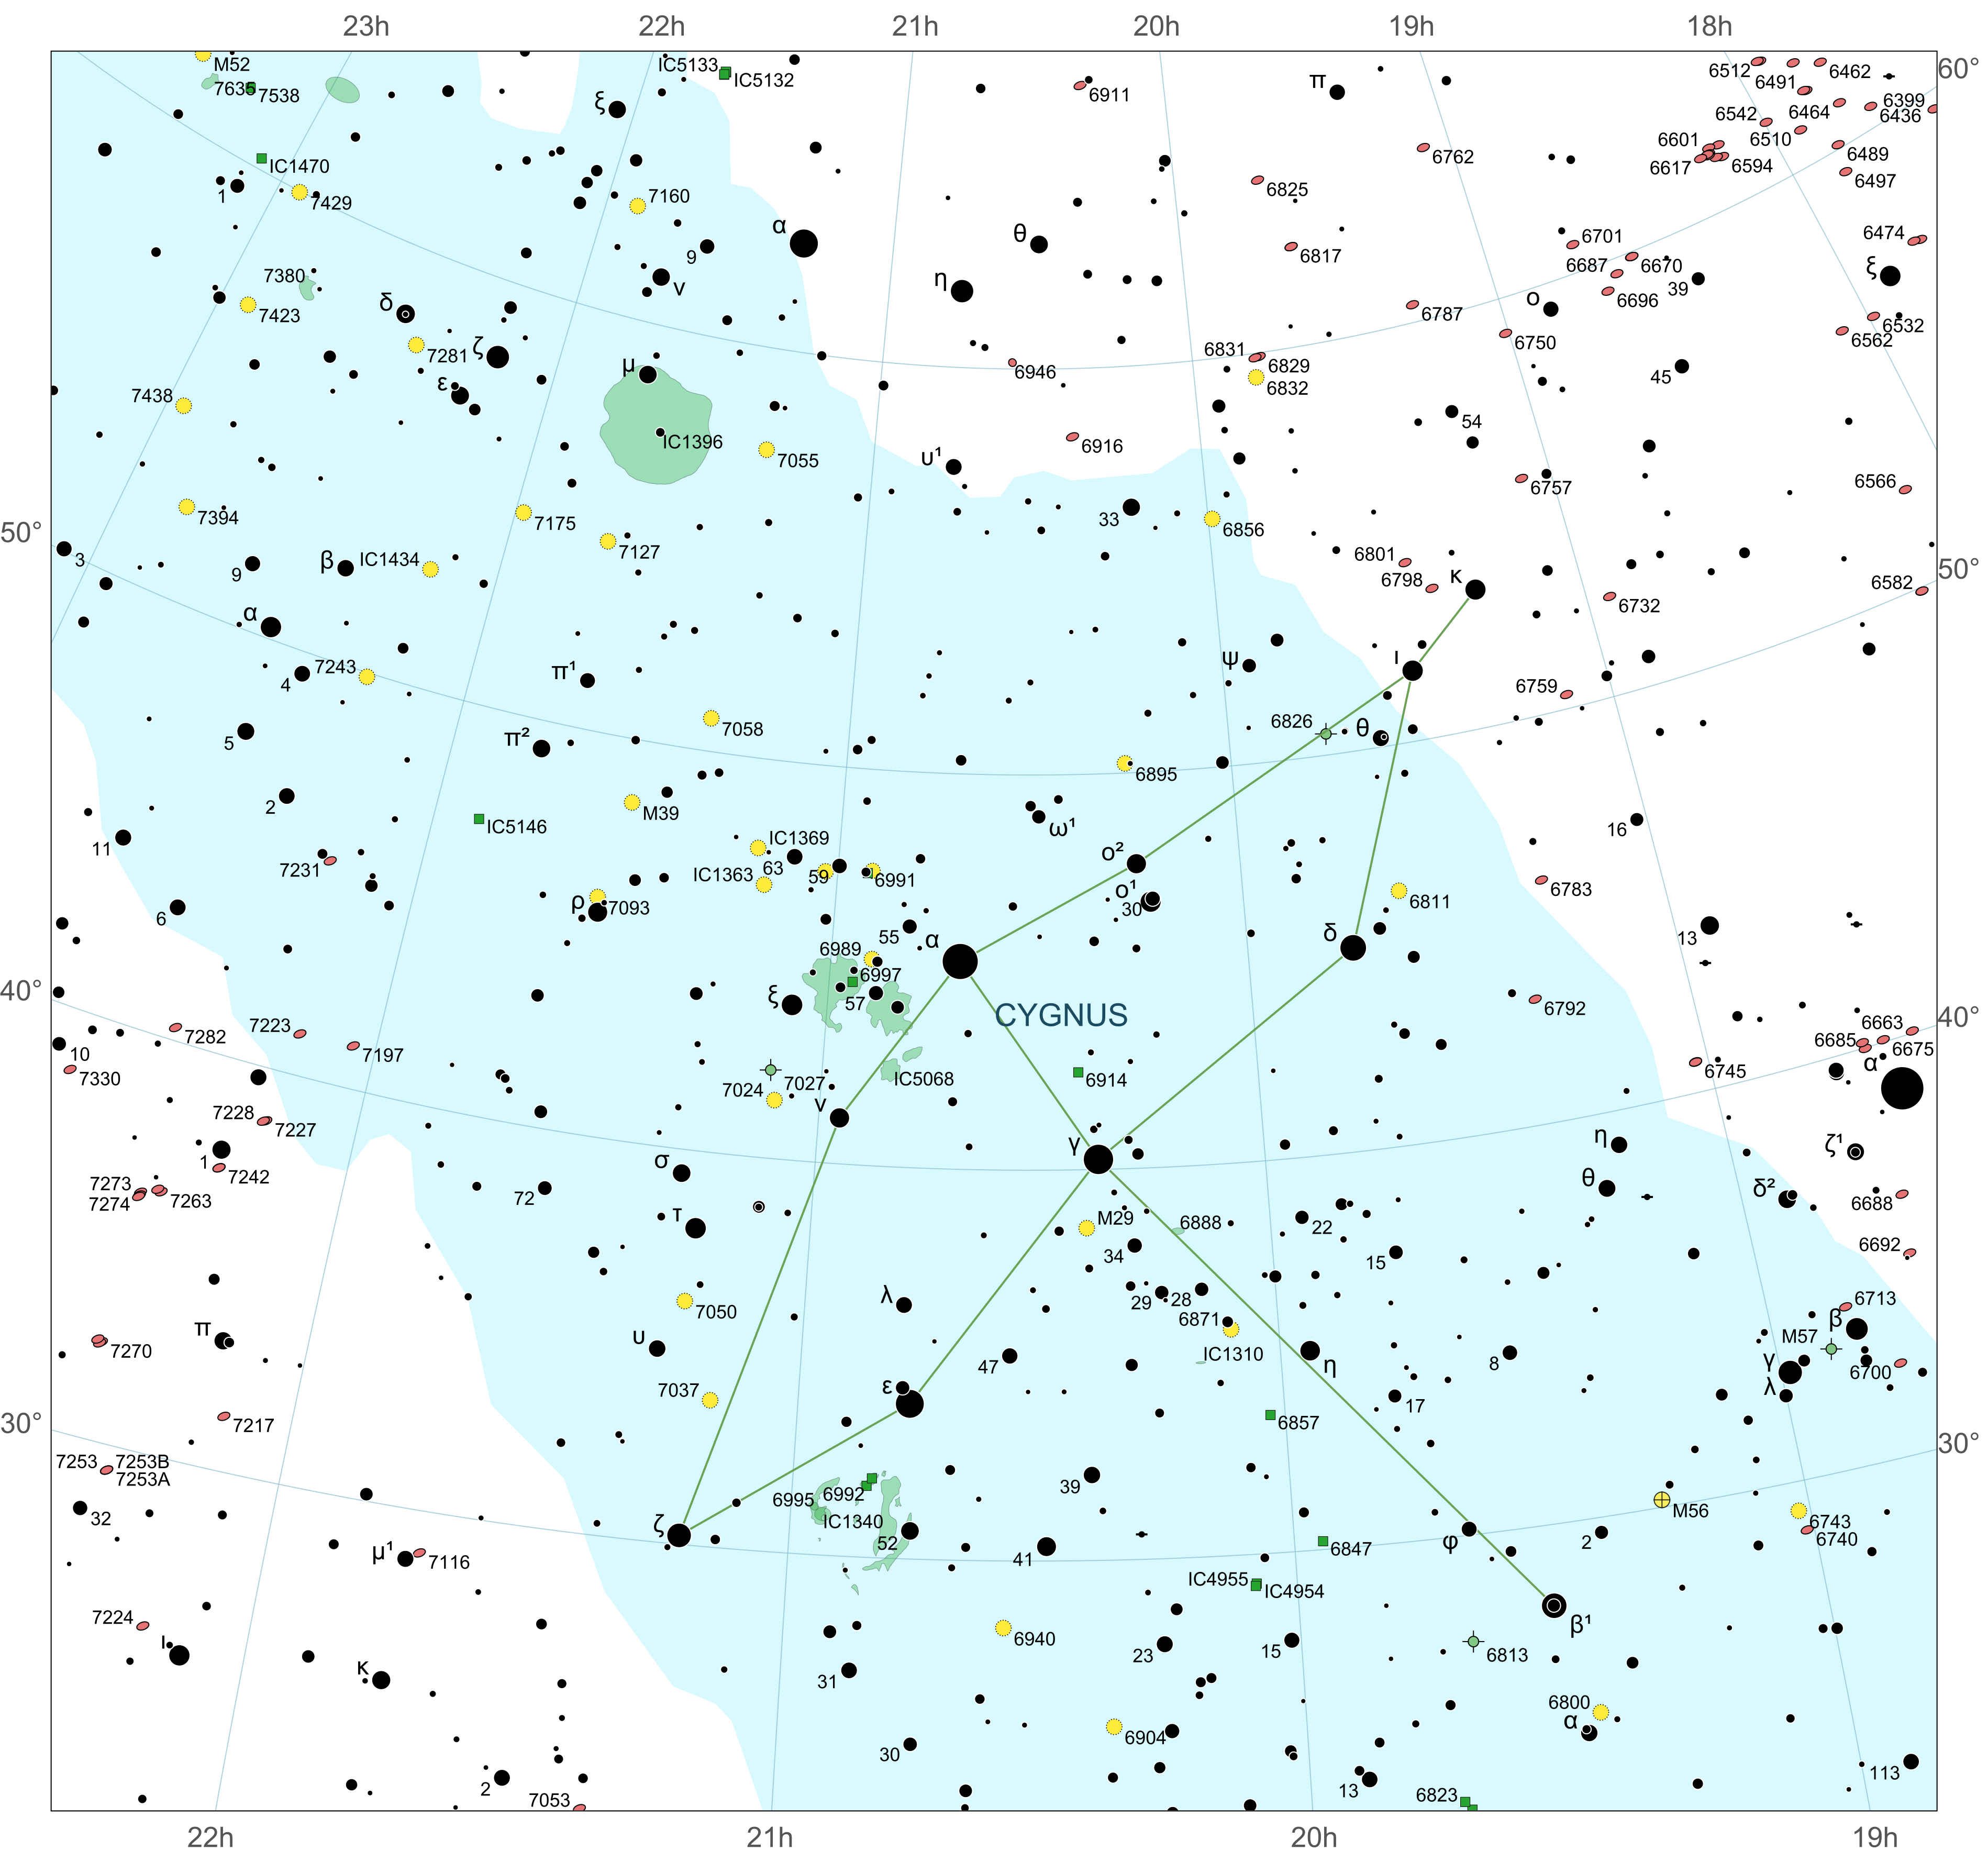

In [7]:
from starplot import MapPlot, DsoType, _
from starplot.models import DSO
# from starplot.styles import extensions

# DEFINE the chart style
# This is where the basic appearance of the plot is defined, by settting a PlotStyle() object
# in this case they call it "style" but that is too generic for the code to be readable to me
# since lots of things have "style" so call it "chartStyle"
#chartStyle = PlotStyle().extend(
#    extensions.STARPLOT,
#    extensions.MAP,
#)

# -------------------------------------------------------------------
# sll CONSTANTS -----------------------------------------------------
# -------------------------------------------------------------------
# These are my values for the chart, defined so I can use them in multiple
# places and not have to constantly find lines of code to tinker with

# --- chart boundary Limits ---------------
# raMIN = 16.0 * 15               # The 15 converts hr -> deg. ra_min is ~ RA at lower right corner of chart (?)
# raMAX = 18.0 * 15               # The 15 converts hr -> deg. ra_max is ~ RA at left corner of chart (?) 26.6
# decMIN = 20.0                   # DEC at right lower bounding box, near lower right corner of chart
# decMAX = 50.0                   # DEC at right top bounding box, near top right corner of chart

# --- SLL FONT SIZE CHOICES ---------------------------
# These also appear in the makeTirionStyle() directives. They appear here because of the special
# handling of Nebulae (draw by outline or small marker) that is done here instead of in the
# makeTirionStyle(). make sure they are consistent if changes are made.
# FUTURE WORK: see if I can handle the nebulae in makeTirionStyle()

sLRG = 60
sMED = 54
sSMALL = 48
sTINY = 36

sSTAR = sSMALL
sDSO = sTINY

# --- Chart Grid Parameters ---------------------------

decSPACE = 10      # spacing of declination lines in degrees
raSPACE = 1 * 15   # spacing of right ascension lines in hours

# --- Object Brightness and Size Limits ---------------

star_BRIGHT = 6.5    # chart limiting magnitude Stars
oc_BRIGHT = 7.0      # min magnitude Open Clusters
gc_BRIGHT = 10.0     # min magnitude Globular Clusters
gx_BRIGHT = 11.0     # min magnitude Galaxies
pn_BRIGHT = 10.0     # min magnitude Planetary Nebulae
bn_BRIGHT = 12.0     # min magnitude Bright Nebulae

oc_SIZE = 20.0        # min size Open Cluster for major axis in ARCMIN
gc_SIZE = 20.0        # min size Globular Cluster for major axis in ARCMIN
gx_SIZE = 5.0         # min size Galaxy for major axis in ARCMIN
pn_SIZE = 1.0         # min size PN for major axis in ARCMIN
bn_SIZE = 10.0        # min size Bright Nebulae for major axis in ARCMIN
dn_SIZE = 10.0        # min size Dark Nebulae for major axis in ARCMIN


# CREATE the MapPlot() object
# again they use the simple moniker "p" (for 'plot' I imagine). It does keep things compact
# so for the moment leave it, but a better moniker might make the code more readable, esp.
# for newbies

trackLabels.clear()    # when I start a new map, clear my label tracking from previous runs

p = makeConstellationChart(iau_id="cyg",padding=4.0)    # make the base chart centered on a constellation

# --- Draw constellation lines, borders ---------------
p.constellations(where=[_.iau_id.isin(["cyg", "del","sge"])])  # plot several constellations
# p.constellations(where=[_.iau_id == "cyg"])                    # just one constellation
# p.constellations()    # draw all constellation lines

# p.constellation_borders(where=[_.iau_id == "cyg"])      # constellation borders


# --------------------------------------------------------------------
#     CONSTELLATION AND GRIDS 
# --------------------------------------------------------------------
p.constellation_labels()

p.gridlines(
    # dec_locations=[d for d in range(0, 90, 10)],  # range(dec min, max, spacingInDeg)
                                                    # with no call defaults to 10 deg grid
                                                    # passing dec_locations[] turns off gridlines
    # ra_locations=[h for h in range(0, 24, 1)],    # range(ra min, max, spacingInDeg) -- uses DEGREES
                                                    # with no call defaults to 1 h grid
                                                    # passing ra_locations[] turns off gridlines
    dec_locations = [d for d in range(0, 90, decSPACE)],  # standard 10 degree grid
    ra_locations=[h for h in range(0, 24*15, raSPACE)],      # standard 1 hour grid
    labels=True,
)


# --------------------------------------------------------------------
#     PLOTTED OBJECTS ON THE CHART 
# --------------------------------------------------------------------
# --- STARS -- plotted with tapered sizes --------------
p.stars(
    where=[
        _.magnitude < star_BRIGHT,    # change the mag limit of plotted stars
    ],
    size_fn=lambda star: getTaperedStarSize(star.magnitude),  # uses my size binning
    label_fn=lambda star: "",  # Suppresses proper names
    bayer_labels=True,         # bayer letters
    flamsteed_labels=True,    # flamsteed numbers
    where_labels=[_.magnitude <= 5.0],     # only label stars brigther than the specified magnitude
)

# --- DOUBLE STARS -- plotted with tapered sizes --------------
# this is a bit complicated because starplot treats double stars as DSOs, not as stars. This bit is to
# plot double stars with the same taper based on their magnitude as used for normal stars, but plot 
# them using the normal Tirion symbol of a black circle with a bar through it
#
# [19 Oct 2026] Modded the double star RA DEC filter to use p.ra_min, p.ra_max, p.dec_min, p.dec_max
#               from the chart bounds computed in makeConstellationChart() for the requested padding

for dso in DSO.all():                     # Iterate through OpenNGC catalog DSOs
    if dso.type == DsoType.DOUBLE_STAR:   # looking for double stars in the listing
        if p.ra_min <= dso.ra <= p.ra_max and p.dec_min <= dso.dec <= p.dec_max:    # only keep what is within chart bounds
        
            mag = dso.magnitude if dso.magnitude is not None else star_BRIGHT
            size_pt = getTaperedStarSize(mag)

            p.marker(                               # this bit makes the tapered marker
                ra=dso.ra,
                dec=dso.dec,
                style={
                    "marker": {
                        "symbol": "circle_line",
                        "fill": "#000000",
                        "stroke": "#000000",
                        "stroke_width": 2.0,
                        "size": size_pt,
                    }
                },
                label=dso.name,                    # double star label
            )


# --- OPEN CLUSTERS -- with limits on what is plotted --------------
p.open_clusters(
    where=[(_.magnitude.isnull()) | (_.magnitude < oc_BRIGHT)],
    where_true_size=[_.maj_ax > oc_SIZE],
)

# --- GLOBULAR CLUSTERS -- with limits on what is plotted ----------
p.globular_clusters(
    where=[(_.magnitude.isnull()) | (_.magnitude < gc_BRIGHT)],
    where_true_size=[_.maj_ax > gc_SIZE],
)

# --- PLANETARY NEBULAE -- with limits on what is plotted ----------
p.planetary_nebula(
    where=[(_.magnitude.isnull()) | (_.magnitude < pn_BRIGHT)],
    where_true_size=[_.size > pn_SIZE],
    # where_true_size=[_.maj_ax > pn_SIZE],
)

# ---- BRIGHT NEBULAE -- with limits on what is plotted ------------
# Here I have a split directive based on the size of the bright nebula, plotting
# small green squares with black outlines for tiny ones, and full transp green
# outlines for extended nebulae (following how Tirion/PSA does it)
#
# [19 Oct 2026] In test plotting I discovered there are a bazillion different
# classifications for bright nebula (see the "nebula_types" below); I had started
# with just "dso_nebula". This is to use the same appearance criteria for
# plotting all bright nebulae.

# Bright Nebula Types (DsoType enums)
nebula_types = [
    DsoType.NEBULA,
    DsoType.EMISSION_NEBULA,
    DsoType.STAR_CLUSTER_NEBULA,
    DsoType.REFLECTION_NEBULA,
    DsoType.HII_IONIZED_REGION,
    DsoType.SUPERNOVA_REMNANT
]

typeValues = [t.value for t in nebula_types]  # make list of strings for identification queries

# -------------------------------------------------
# LARGE NEBULAE: True Outlines, Transparent Shading
# -------------------------------------------------

for dso_type in nebula_types:         # this sets for all nebulae the display parameters for outline drawing
    dso_style = p.style.get_dso_style(dso_type)
    dso_style.marker.fill = "#26A631"      # ltTransGreen = #A5D6A7, emerald = #26A631, dkGreen = #1B5E20,
    dso_style.marker.stroke = "#000000"    # Outline: #1B5E20 = Dark green, #000000 = Black
    dso_style.marker.stroke_width = 1.0
    dso_style.marker.opacity = 0.35          # 35% -- lets stars/gridlines show through
    dso_style.label.font_size = sDSO         # font size for label
    dso_style.label.fill = "#000000"

p.dsos(
    where=[
        _.type.isin(typeValues),
        (_.magnitude.isnull()) | (_.magnitude < bn_BRIGHT),
        _.maj_ax > bn_SIZE,
    ],
    where_true_size=True,                    # Draws geoemtric borders of the nebula
)

# -------------------------------------------------
# SMALL NEBULAE: Square Markers
# -------------------------------------------------

for dso_type in nebula_types:
    dso_style = p.style.get_dso_style(dso_type)
    dso_style.marker.symbol = "square"       # Square marker shape
    dso_style.marker.fill = "#26A631"      # ltTransGreen = #A5D6A7, emerald = #26A631, dkGreen = #1B5E20,
    dso_style.marker.stroke = "#000000"    # Outline: #1B5E20 = Dark green, #000000 = Black
    dso_style.marker.stroke_width = 1.0
    dso_style.marker.size = 18               # Marker size in points
    dso_style.marker.opacity = 1.0           # Opaque
    dso_style.label.font_size = sDSO         # font size for label
    dso_style.label.fill = "#000000"

p.dsos(
    where=[
        _.type.isin(typeValues),
        (_.magnitude.isnull()) | (_.magnitude < bn_BRIGHT),
        (_.maj_ax <= bn_SIZE) | (_.size.isnull()),
    ],
    where_true_size=False,                # Draw square as point marker for neubla
)


# ---- DARK NEBULAE -- with limits on what is plotted ------------
# Here I have a split directive based on the size of the dark nebula, plotting
# small x markers for tiny ones, and full dotted outliens for extended dark
# nebulae (following how Tirion/PSA does it)

# -------------------------------------------------
# LARGE DARK NEBULAE: True Outlines, Transparent Shading
# -------------------------------------------------
with p.style.dso_dark_nebula as darkneb:
    darkneb.marker.fill = "#E0E0E0"         # Light Grey
    darkneb.marker.stroke = "#000000"       # Outline: #000000 = Black
    darkneb.marker.dash_array = "dotted"      # dotted outlines
    darkneb.marker.stroke_width = 1.0
    darkneb.marker.opacity = 0.35             # 35% -- lets stars/gridlines show through

    p.dark_nebula(
        where_true_size=[_.maj_ax > dn_SIZE],   # Use true outline large Dark Nebs
    )

# -------------------------------------------------
# SMALL DARK NEBULAE: X Markers
# -------------------------------------------------
with p.style.dso_dark_nebula as darkneb:
    darkneb.marker.symbol = "star_4"          # star_4 is a "cross star" and the closest to an "X" in starplot
    darkneb.marker.fill = "#000000"         # Fill: #000000 = Black
    darkneb.marker.stroke = "#000000"       # Outline: #000000 = Black
    darkneb.marker.stroke_width = 1.0
    darkneb.marker.size = 8                   # Marker size in points

    p.dark_nebula(
        where_true_size=[_.maj_ax < dn_SIZE],   # Use true outline large Dark Nebs
    )


# --- GALAXIES -- with limits on what is plotted -------------------

# -----------------------------
# --- LARGE GALAXIES ----------
# -----------------------------
p.galaxies(
    where=[
        (_.magnitude < gx_BRIGHT) | (_.magnitude.isnull() & _.name.startswith("NGC")),  # if no brightness, only keep NGC
        _.maj_ax > gx_SIZE,
    ],
    where_true_size=True,   # For large galaxies, plots true size
    label_fn=standardLabel, # uses my clean label function to strip extra OpenNGC NED labeling
)

# -----------------------------
# --- SMALL GALAXIES ----------
# -----------------------------
p.galaxies(
    where=[
        (_.magnitude < gx_BRIGHT) | (_.magnitude.isnull() & _.name.startswith("NGC")),  # if no brightness, only keep NGC
        (_.maj_ax <= gx_SIZE) | (_.maj_ax.isnull()),
    ],
    where_true_size=False,  # Forces fixed point marker rendering
    label_fn=standardLabel, # uses my clean label function to strip extra OpenNGC NED labeling
)

# -------------------------------------------------------------------------------
# ---- Add Milky Way ------------------------------------------------------------
# -------------------------------------------------------------------------------
# Starplot has a built-in function for the main Milky Way isophote. Apparently, if
# I would like the two-level isophote common in Tirion/PSA style maps, I'll have
# to overlay an additional polygon outline, which means I need to know the polygon
# of the isophote!  For now, just call the main isophote.

p.milky_way()

# -------------------------------------------------------------------------------
# ---- Add Telrad Rings at desired object location ------------------------------
# -------------------------------------------------------------------------------

telradCenter = DSO.get(m="11")              # messier object
# telradCenter = DSO.get(ngc="6205")        # ngc object

makeTelrad(p, ra=telradCenter.ra, dec=telradCenter.dec)
# makeTelrad(p, ra=telradCenter.ra, dec=telradCenter.dec, color="#FF0000", stroke_width=2.0) # override plot color/stroke

# ---- INLINE DISPLAY: JUPYTER --------------------------------------------------
# I want to display inline while I am working on charts, not export to file. Since starplot
# uses SVG as its native display format, some workaround is neded. Solution seems to be
# using a temporary directory that Jupyter will clean up automatically at the end.
# Use this code for inline display:
with tempfile.TemporaryDirectory() as tmpDir:
    tmpFile = Path(tmpDir) / "aquarius.png"   # this defines the temporary PNG in the tmpDir
    # tmpFile = Path(tmpDir) / "aquarius.svg"   # this defines the temporary SVG in the tmpDir
    p.export(str(tmpFile))                      # this exports the temporary IMAGE to
    display(Image(filename=str(tmpFile)))       # this displays PNG in the Jupyter window
    # display(SVG(filename=str(tmpFile)))         # this dispalys SVG in the Jupyter window
